In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import math
#plt.style.use('seaborn-whitegrid')

In [2]:
from typing import Dict, List, Union, Optional
from pathlib import Path

def get_classification_TTA_paths(
    source: str,
    target: str,
    modelname: str,
    foldernames: Dict[str, str],
    augs: List[str],
    selected_augs: Optional[Dict[str, List[int]]] = None,
    base_folder: Union[str, Path] = Path(
        "/g/kreshuk/talks/domain_gap/experiments/patch_classification"
    ),
):
    # check if base_folder is a string
    if isinstance(base_folder, str):
        base_folder = Path(base_folder)

    pred_folder = base_folder / Path(
        f"{source}_to_{target}/consistency/predictions/{modelname}"
    )
    # check if the folder exists
    if not pred_folder.exists():
        raise FileNotFoundError(f"Folder {pred_folder} does not exist.")

    paths: Dict[str, List[Path]] = {}
    for aug in augs:
        folder_path = pred_folder / foldernames[aug]
        # check if the folder exists
        if not folder_path.exists():
            raise FileNotFoundError(f"Folder {folder_path} does not exist.")
        aug_paths = list(
            folder_path.glob(f"{source[0].upper()}to{target[0].upper()}_{aug}*.npz")
        )
        if selected_augs:
            aug_paths = [aug_paths[i] for i in selected_augs[aug]]

        paths[aug] = aug_paths
    return paths

In [3]:
def classification_TTA_predictions(
    source: str,
    target: str,
    modelname: str,
    foldernames: Dict[str, str],
    augs: List[str],
    selected_augs: Dict[str, List[int]] = None,
):
    predictions = []
    soft_predictions = []
    gt_labels = []
    f1_scores = []
    aug_params = []

    paths = get_classification_TTA_paths(
        source=source,
        target=target,
        modelname=modelname,
        foldernames=foldernames,
        augs=augs,
        selected_augs=selected_augs,
    )
    for aug in augs:
        for path in paths[aug]:
            with np.load(path, "r") as data:
                predictions.append(data["predictions"])
                soft_predictions.append(data["soft_predictions"])
                gt_labels.append(data["labels"])
                f1_scores.append(data["f1_score"])
                if "aug_params" in data:
                    aug_params.append(data["aug_params"])
    preds = np.vstack(predictions)
    soft_preds = np.vstack(soft_predictions)
    labels = np.vstack(gt_labels)
    f1s = np.vstack(f1_scores)
    if len(aug_params) > 0:
        aug_params = np.vstack(aug_params)

    return preds, soft_preds, labels, f1s, aug_params

In [4]:
def plot_metric_vs_F1_aug_sweep2(
    metric_scores,
    f1_scores,
    transfers,
    aug_name,
    aug_params,
    selected_alphas,
    metric_name,
    figsize=(40, 10),
    xlim=(0.2, 1),
    fontsize=20,
    point_size=50,
    f1_per_aug=False,
    legend_size=20,
    save_path=None,
):
    #source_markers = {"E": "o", "H": "x", "R": "^"}
    colors = ['r', 'g', 'b', 'y', 'm', 'c', 'k', 'lime', 'blueviolet', 'gold', 'aquamarine', 'rosybrown', 'olive', 'deeppink']
    markers = ['o', 'x', '^', 's', '<', '>', 'v', 'd', 'p', 'h', 'D', 'P', 'X', '*', '8', '1', '2', '3', '4', 'H', '+', '|', '_']
    assert len(metric_scores) == len(
        f1_scores
    ), "metric scores and f1s must have the same length"
    # indices (into the full aug_params/metric_scores/f1_scores arrays) to plot for this aug
    alphas = selected_alphas.get(aug_name) if selected_alphas else None
    selected_idx = np.arange(len(aug_params)) if alphas is None else np.atleast_1d(alphas)
    selected_params = [aug_params[idx] for idx in selected_idx]
    f = plt.figure(figsize=figsize)
    cmap = mcolors.ListedColormap(colors[:len(transfers)])
    norm = mcolors.BoundaryNorm(np.arange(len(transfers) + 1), cmap.N)
    for i, transfer in enumerate(transfers):
        color = cmap(i)
        for pos, idx in enumerate(selected_idx):
            if f1_per_aug:
                f1s = f1_scores[i][idx + 1]
                f1_label = f"F1 ({aug_name})"
            else:
                f1s = f1_scores[i][0]
                f1_label = "F1-score"
            _= plt.scatter(
                metric_scores[i][idx],
                f1s,
                marker=markers[pos],
                s=point_size,
                color=color,
            )
    for pos, aug_param in enumerate(selected_params):
        _ = plt.scatter(
            [], [], marker=markers[pos], label=str(aug_param), color="black"
        )
    # Create the colorbar
    cbar = plt.colorbar(
        plt.cm.ScalarMappable(norm=norm, cmap=cmap),
        ax=plt.gca(),
        boundaries=np.arange(len(transfers) + 1),
        ticks=np.arange(len(transfers)) + 0.5,
    )
    cbar.set_ticklabels(transfers, fontsize=fontsize - 5)
    cbar.set_label("Transfer", fontsize=fontsize)
    _ =plt.title(
        f"{aug_name}",
        fontsize=fontsize,
    )
    _ = plt.xlabel(metric_name, fontsize=fontsize)
    _ = plt.xlim(xlim[0], xlim[1])
    _ = plt.ylabel(f1_label, fontsize=fontsize)
    _ = plt.tick_params(labelsize=fontsize-2)
    lgnd = plt.legend(prop={"size": legend_size})
    for a in range(len(lgnd.legend_handles)):
        lgnd.legend_handles[a]._sizes = [point_size]
    plt.grid()
    plt.tight_layout()
    if save_path is not None:
        f.savefig(save_path, format="svg", bbox_inches="tight", pad_inches=0)
    plt.show()



In [5]:
from numpy.typing import NDArray
from typing import Any

from numpy.typing import NDArray
from typing import Any
from scipy.stats import entropy

def calculate_entropy_per_aug(preds: NDArray[Any]) -> NDArray[Any]:
    entropies = np.zeros((len(preds) - 1, preds.shape[1]))
    for i in range(len(preds) - 1):
        probs = np.zeros((preds.shape[1], 2))
        p1 = np.mean(preds[np.r_[0, i + 1]], axis=0)
        probs[:, 0] = 1 - p1
        probs[:, 1] = p1
        entropies[i] = entropy(probs, axis=1)
    return entropies

In [6]:
source_datasets = ['epfl', 'Hmito', 'Rmito']
# target_datasets = ['epfl', 'Hmito', 'Rmito', 'VNC']
target_datasets = ['epfl', 'Hmito', 'Rmito', 'VNC']
augmentations = ['Brt', 'Ctr', 'Gamma', 'Gauss']
sweep_folders = {
    'None': 'aug_sweep',
    'Brt': 'aug_sweep',
    'Ctr': 'aug_sweep2',
    'Gamma': 'aug_sweep2',
    'Gauss': 'aug_sweep',
}
sweep_folders_Hmito = {
    'None': 'aug_sweep',
    'Brt': 'aug_sweep',
    'Ctr': 'aug_sweep',
    'Gamma': 'aug_sweep',
    'Gauss': 'aug_sweep',
}
source_models = {'epfl': 'RN18_epfl80_aug5_soft', 'Hmito': 'RN18_Hmito80_aug2_soft', 'Rmito': 'RN18_Rmito80_aug3_soft'}

In [7]:
# indices into aug_params to plot for each augmentation; None means "all"
selected_alphas = {
    "Brt": None,
    "Ctr": np.r_[1:13],
    "Gamma": None,
    "Gauss": None,
}


[0.07038174 0.10440247 0.22388356 0.40732176 0.38167658]


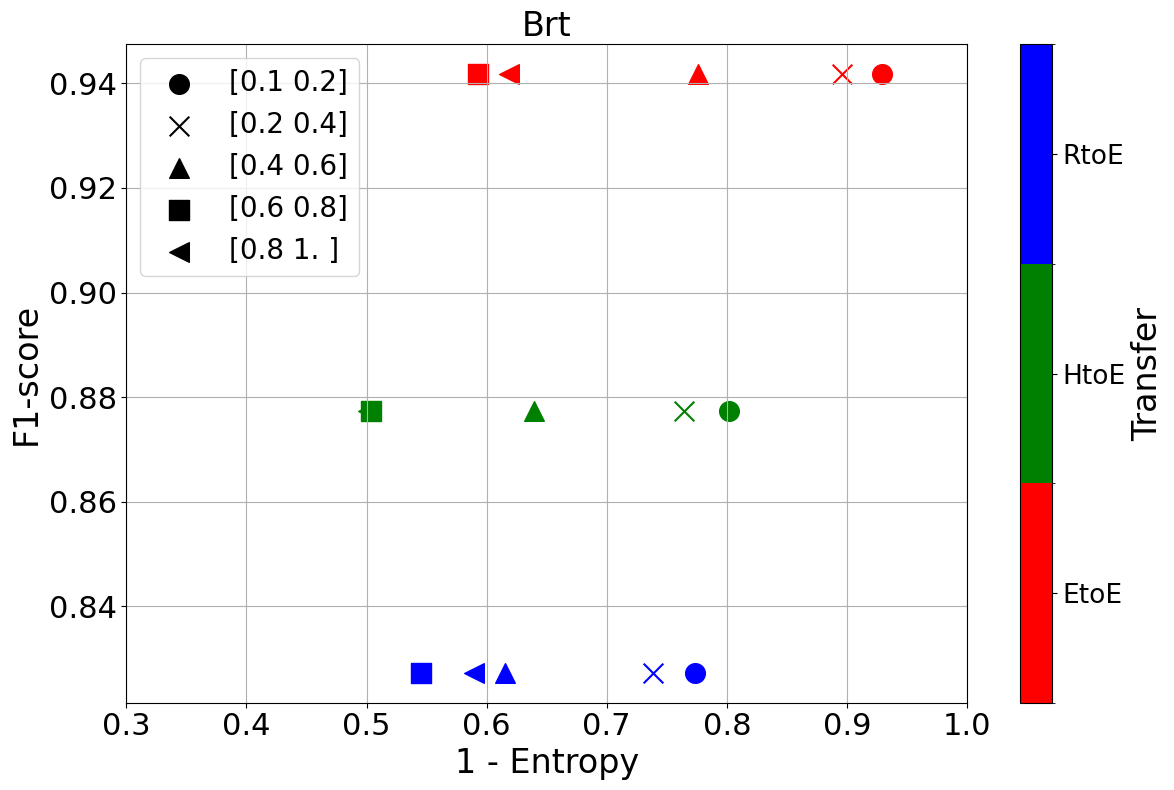

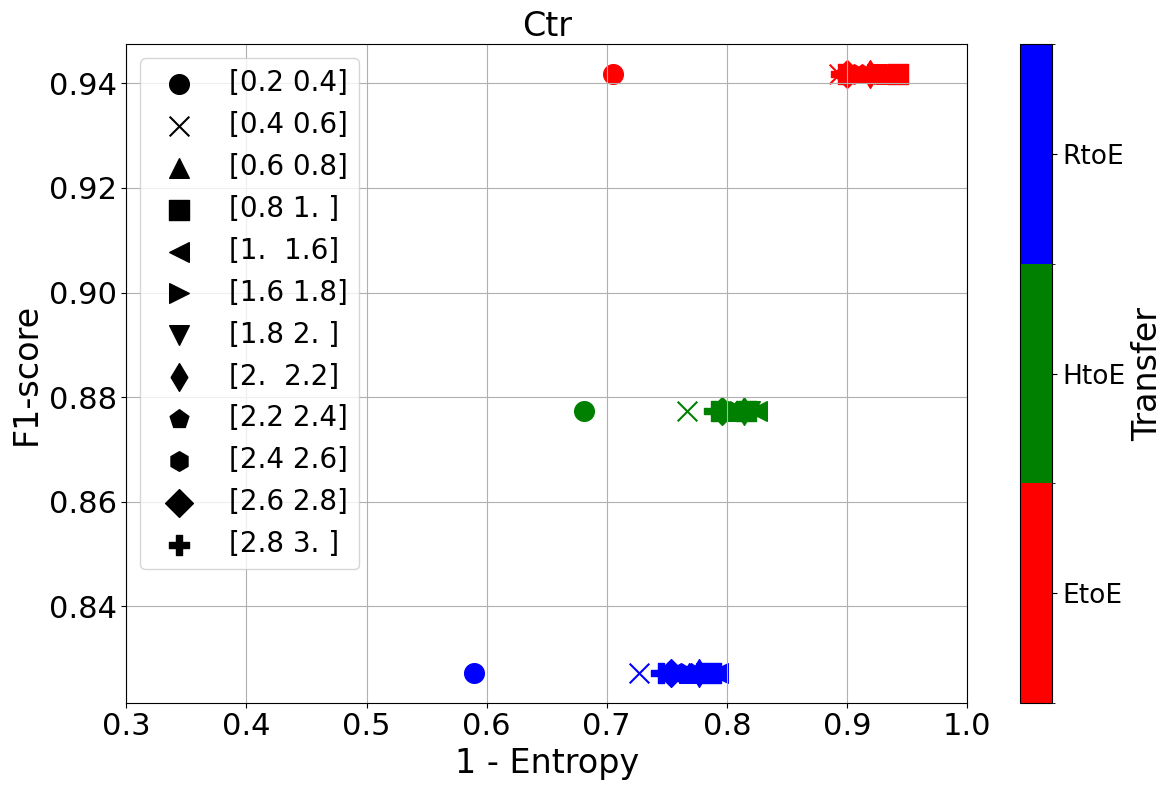

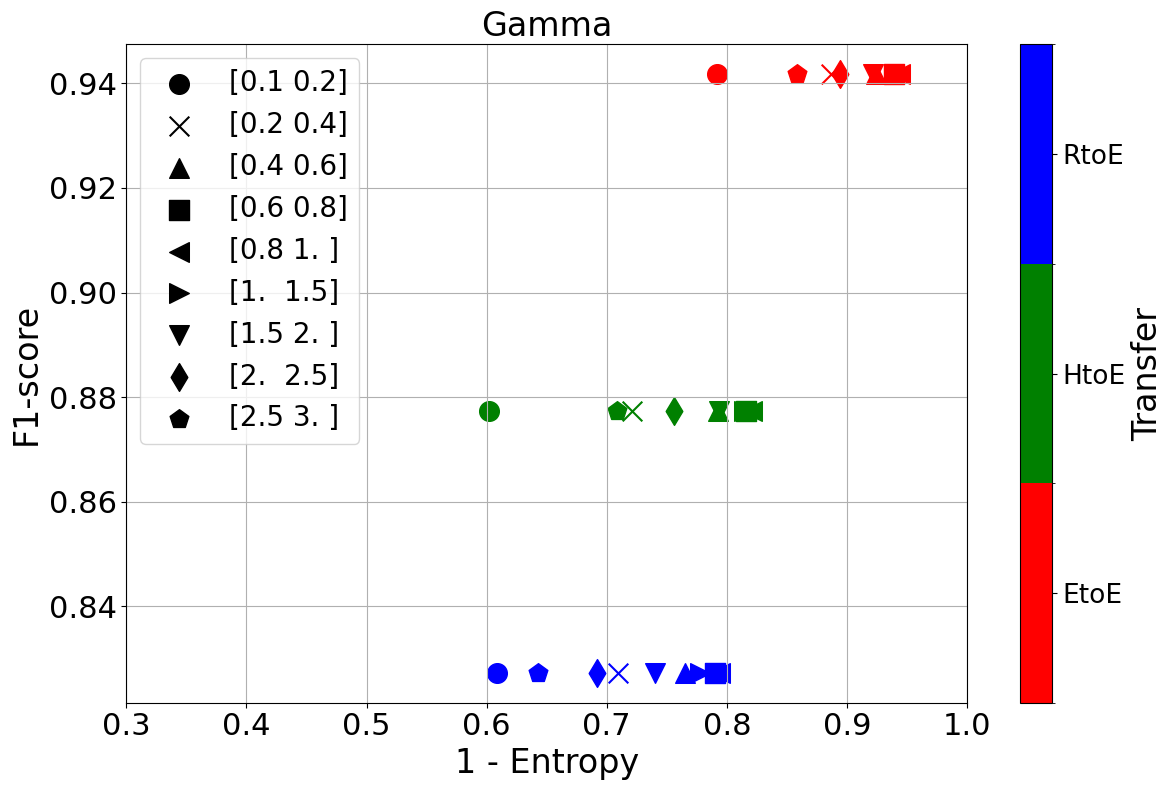

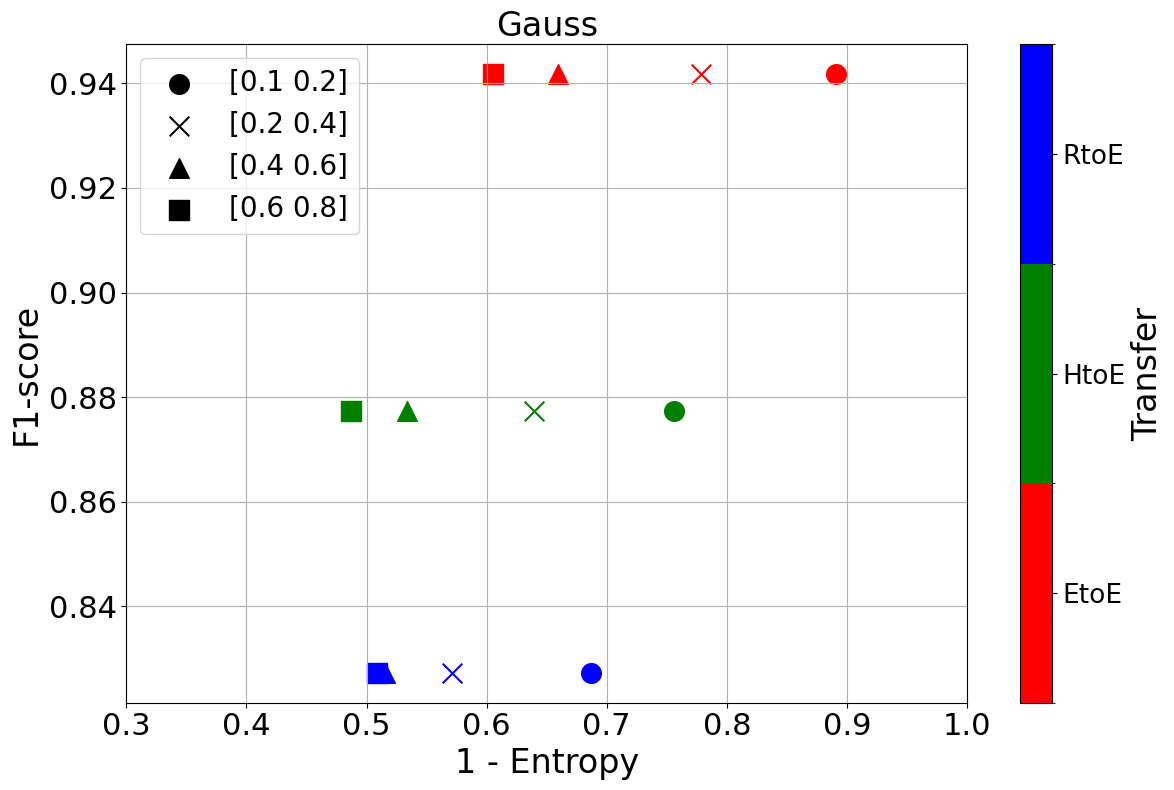

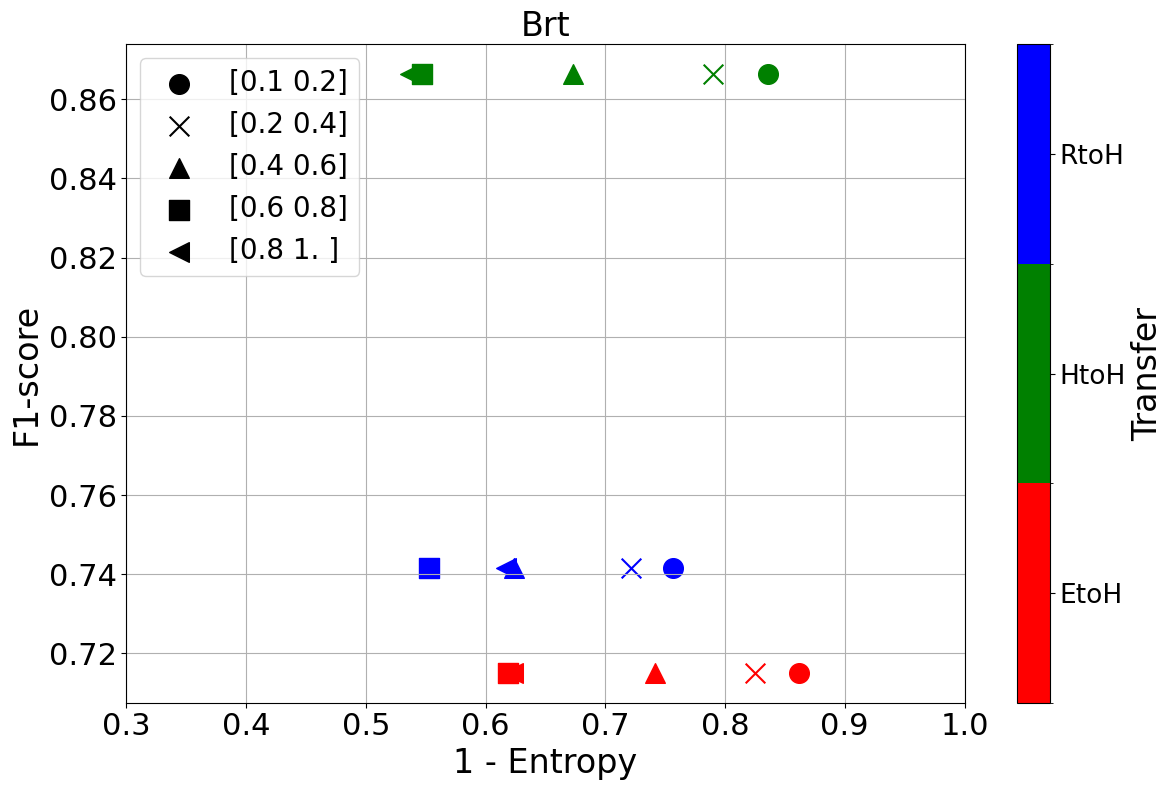

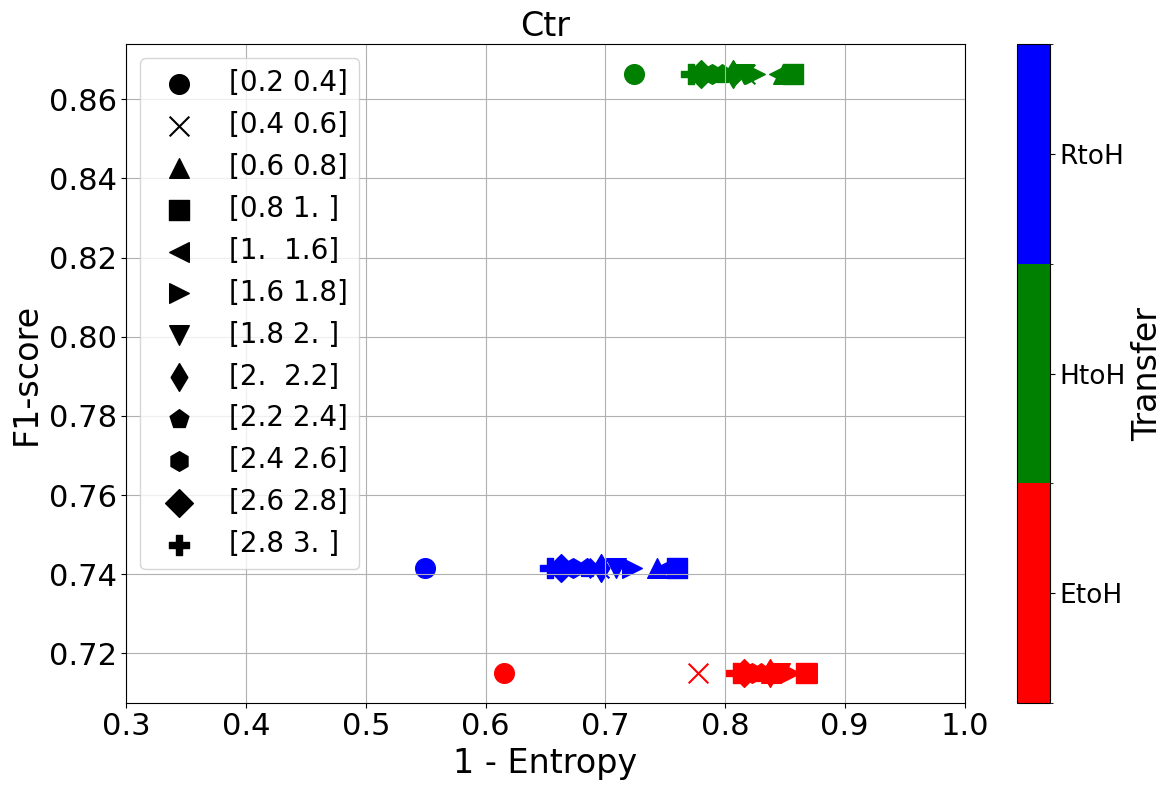

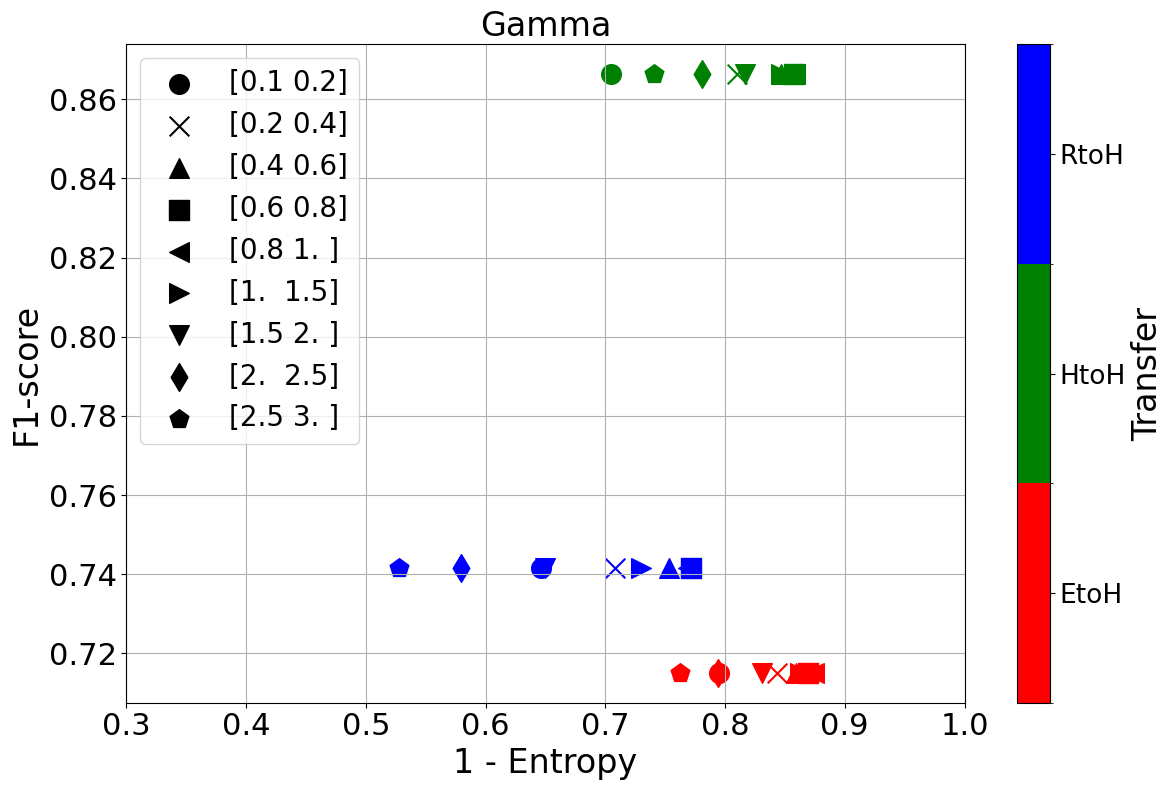

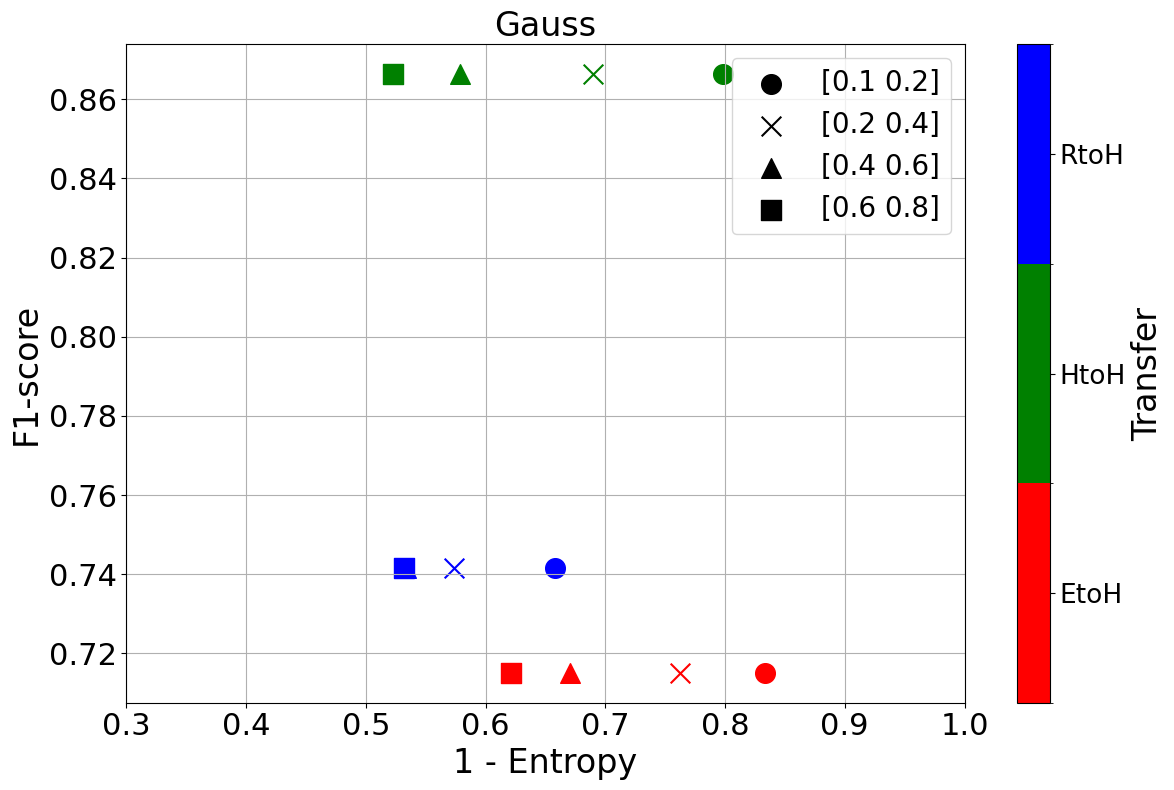

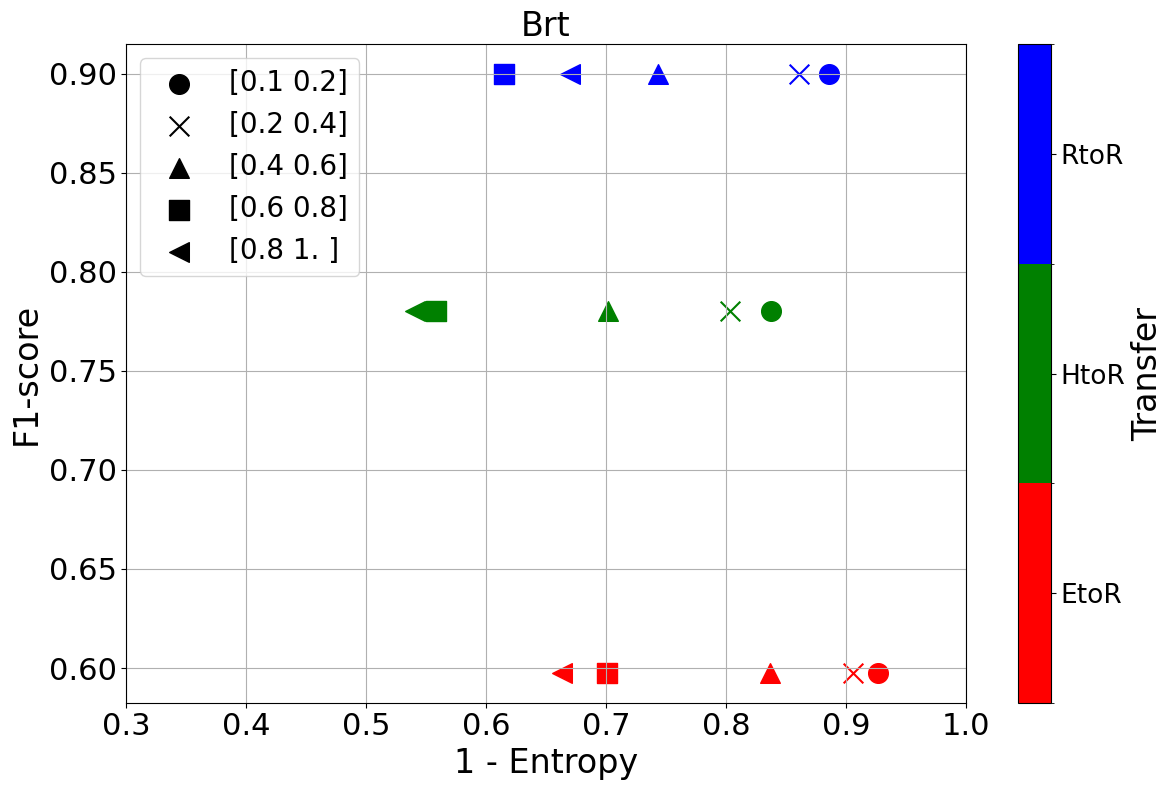

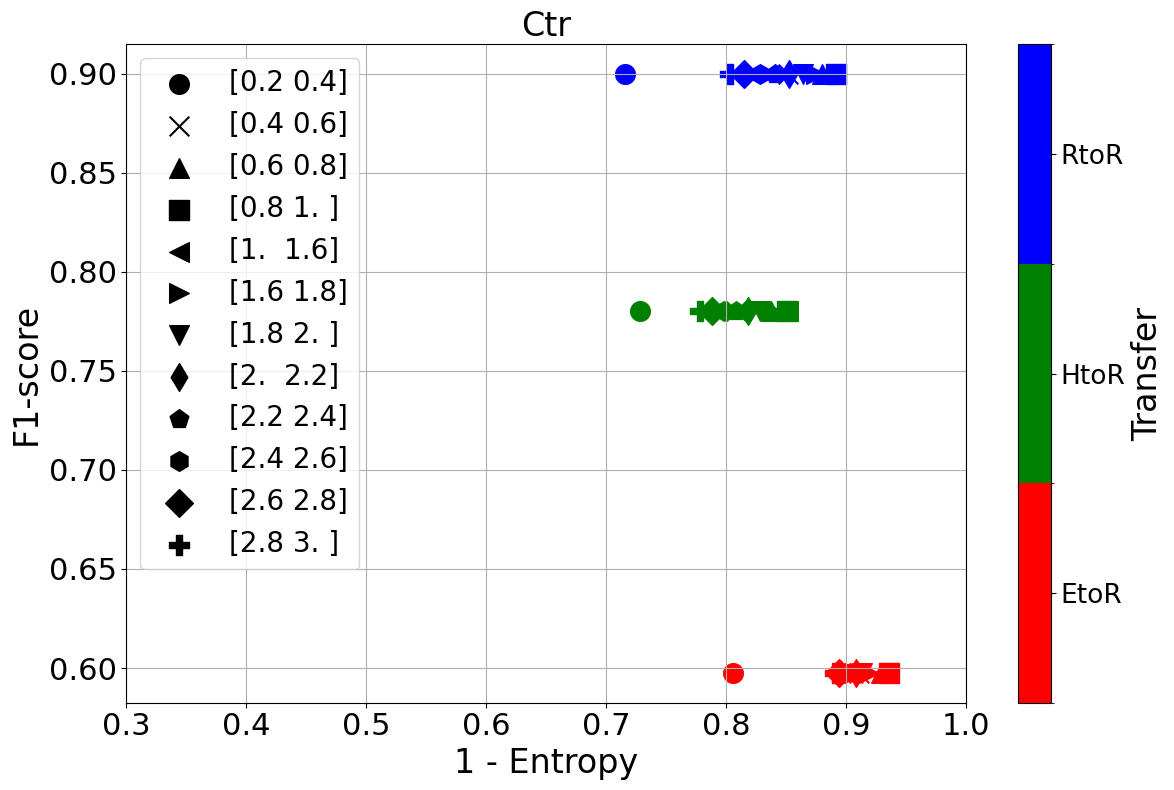

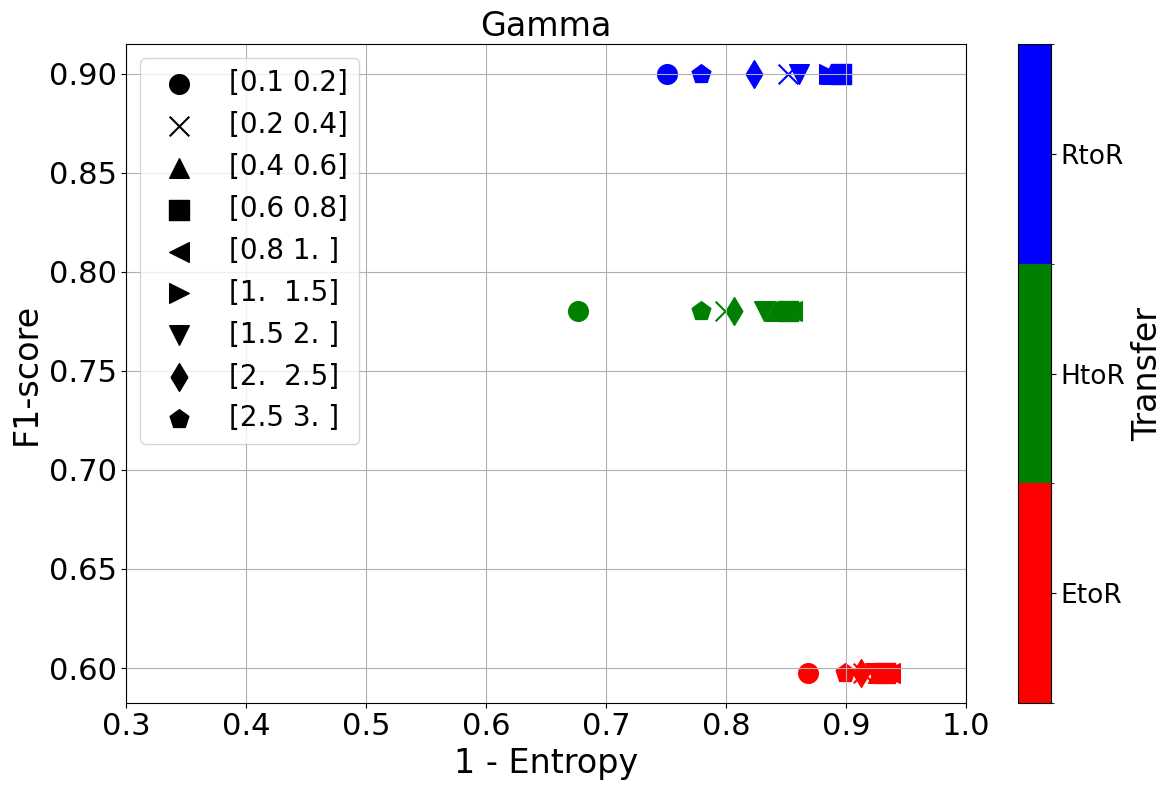

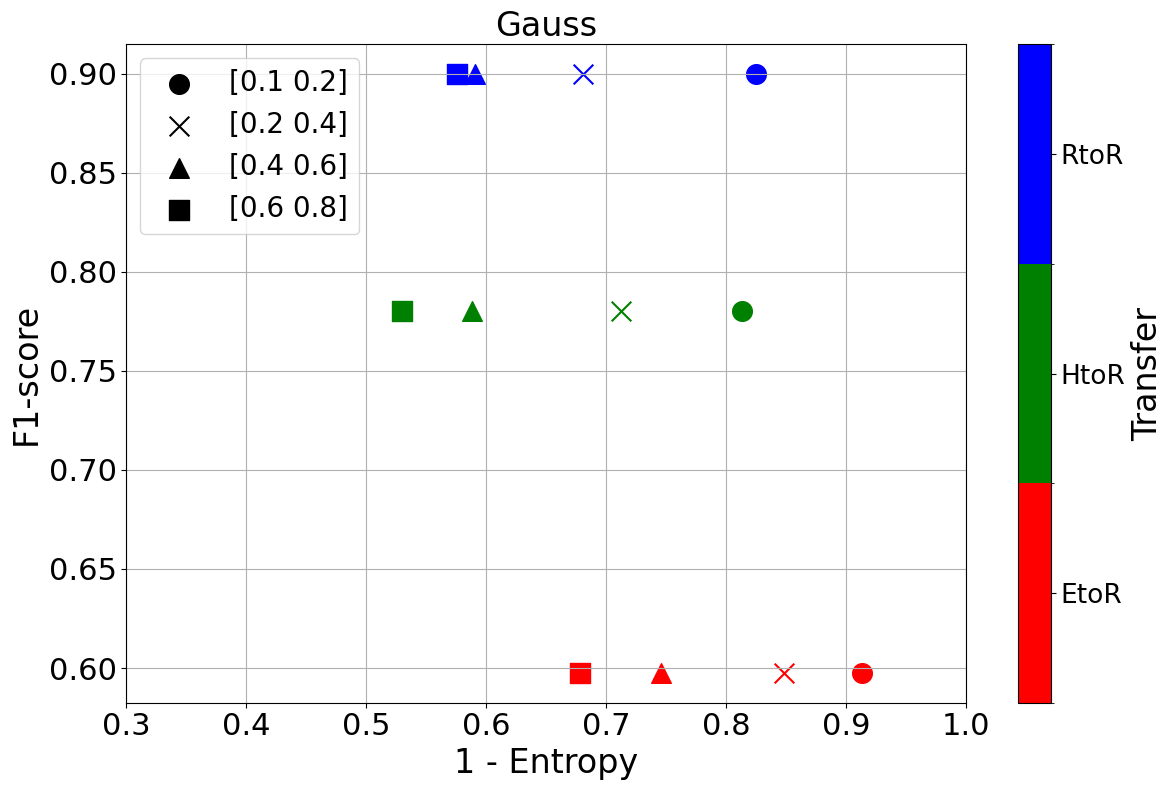

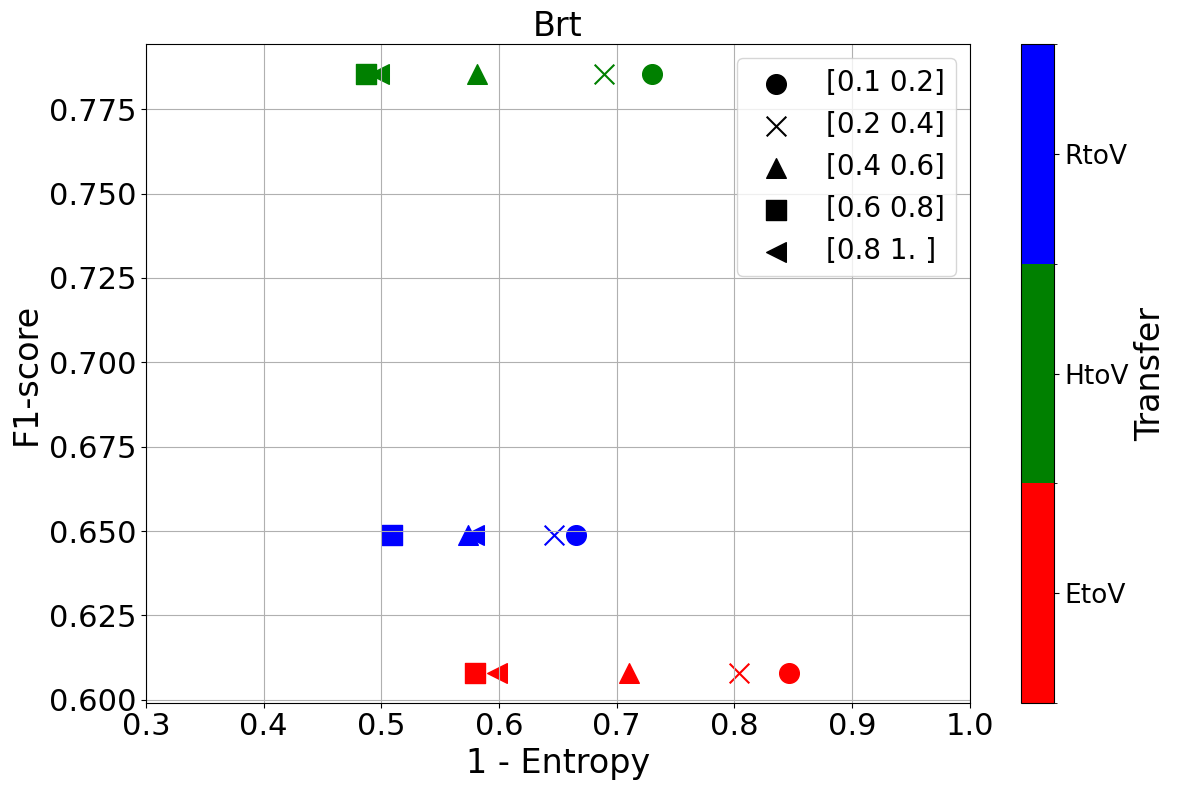

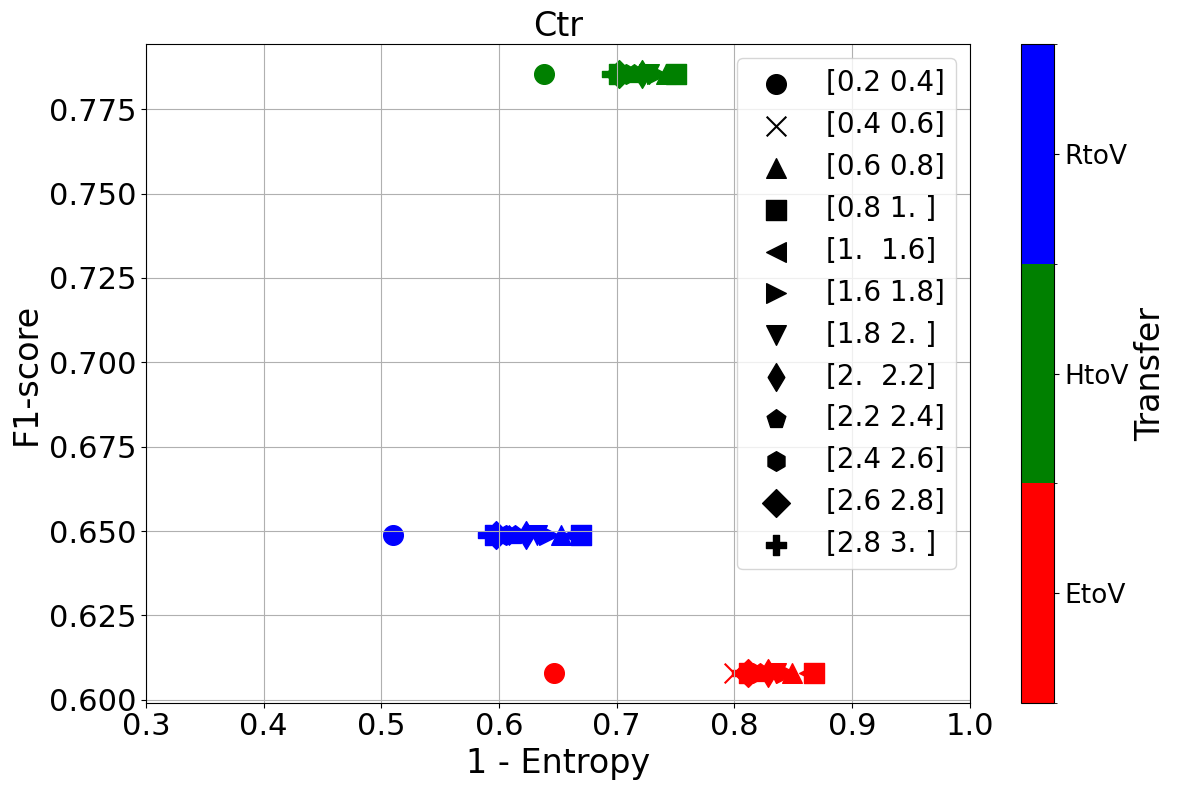

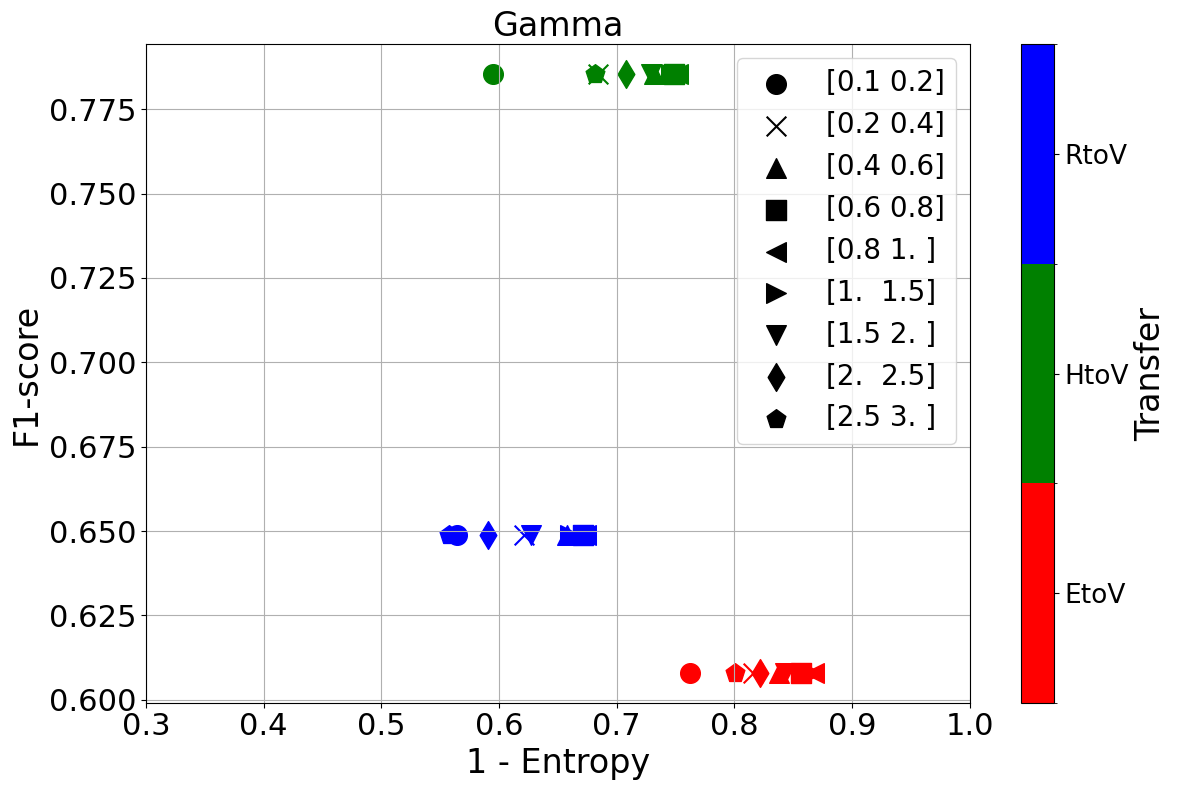

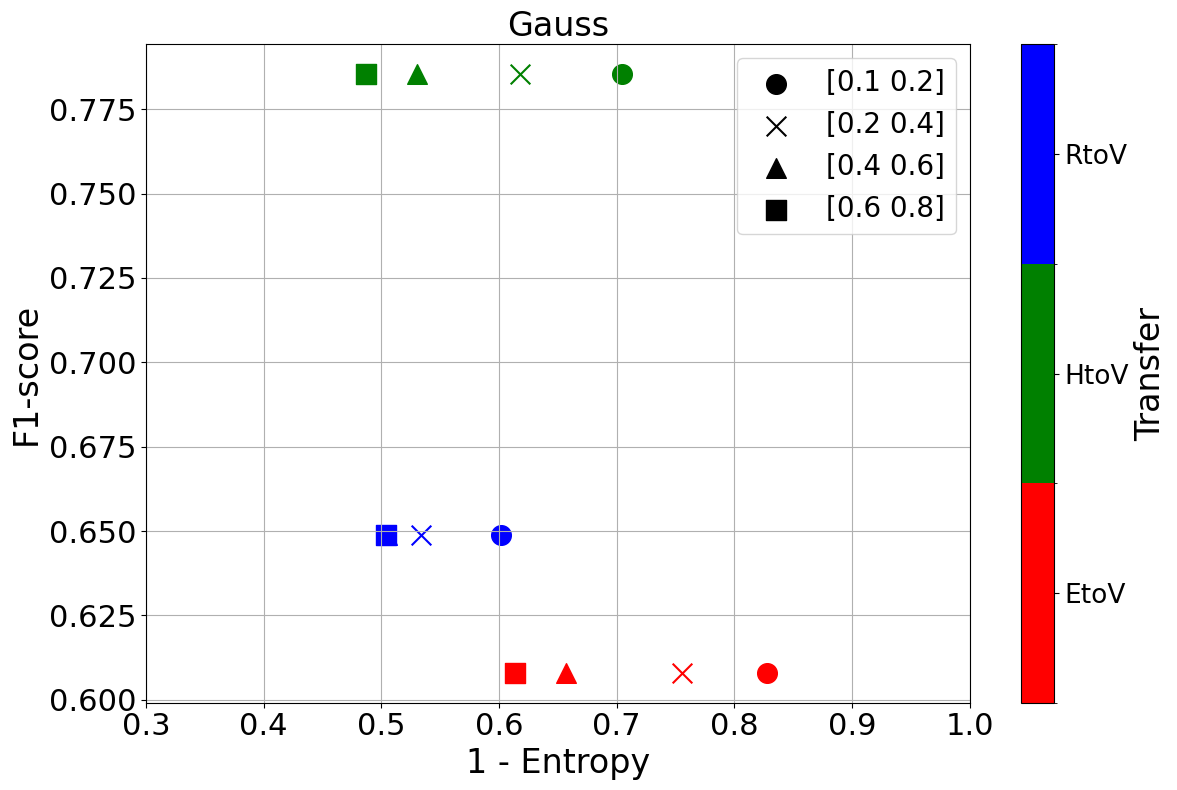

In [11]:
for target in target_datasets:
    for aug in augmentations:
        Entropy_scores = []
        F1_scores = []
        transfers = []
        for source in source_datasets:
            transfer = f"{source[0].upper()}to{target[0].upper()}"
            transfers.append(transfer)
            
            if source == 'Hmito':
                folders = sweep_folders_Hmito
            else:
                folders = sweep_folders

            preds, soft_preds, gt, f1, aug_params = classification_TTA_predictions(
                source, target, modelname=source_models[source], foldernames=folders, augs=["None", aug]
            )
            entropies = calculate_entropy_per_aug(
                soft_preds
            )
            Entropy_scores.append(1 - entropies.mean(axis=1))
            F1_scores.append(f1)
            #print(f"{transfer}: {aug} EI std: {np.std(EI_mean)}")
        #num = EI_scores[0].shape[0]
        # set nrows and ncols based on num, nrows*ncols >=num but the smallest number posisble
        # that satisfies this condition
        #nrows, ncols = find_plot_dimensions(num)
        #metric_pearsonr(Entropy_scores, F1_scores, aug_params)
        plot_metric_vs_F1_aug_sweep2(
            Entropy_scores,
            F1_scores,
            transfers,
            aug,
            aug_params,
            selected_alphas,
            metric_name="1 - Entropy",
            point_size=200,
            fontsize=24,
            figsize=(12, 8),
            xlim=(0.3,1),
            save_path=f"/g/kreshuk/talks/model_ranking/notebooks/thesis/mitochondria/classification/sweeps/Entropy_{target}_{aug}.svg"
        )
